# Data VZP: akční segmenty pozvaných žen

Segmenty mají být **prakticky použitelné**: jasné pravidlo nad sloupci VZP, srozumitelný název
a hypotéza, jakou podporu nabídnout. Pravidla jsou v `config/segments_vzp.yaml`; pozvánka patří do
prvního segmentu, jehož pravidlo platí. Navazuje na `03_segmentace.ipynb` v původním repozitáři (stejný postup na
syntetických datech); segmenty, které potřebují sloupce, jež VZP nedodala (hospitalizace,
vzdálenost k centru, věk 75+), tu nejsou.

Kontroly:
* **model hazardu na pozvánku** (pořadová pásma, jako `vzp_hazard.ipynb`): predikce a rozptyl
  rizika uvnitř segmentů, test 2024,
* **shlukování podle SHAP**: najdou shluky velkou skupinu, kterou pravidla přehlížejí?

Jednotka je pozvánka; v roce 2024 má každá žena právě jednu, takže tam pozvánka = žena.
Notebook ukazuje jen agregáty.

## Hlavní zjištění

1. **Devět pravidel nese většinu informace modelu.** Samotný segment seřadí ženy s AUROC 0,80
   (do 12 měsíců), celý model 0,84. Uvnitř segmentů model rozlišuje už jen slabě (AUROC 0,63–0,74).
2. **Účast mezi segmenty se liší dvacetinásobně** (2024, do 12 měsíců): první pozvánka 55 %,
   vypadlé z návyku 39 % a 26 %, bez screeningu u gynekologa 21 %, s jinou prevencí 13 %,
   opakovaně nereagující 5 %, v kontaktu se zdravotnictvím 5 %, odpojené 3 %.
3. **Kdo nepřišel (2024, 207 tisíc žen):** 27 % opakovaně nereagující s jinou prevencí,
   20 % ženy chodící ke gynekologovi, 12 % zvané málokrát s jinou prevencí, 11 % odpojené,
   8 % v kontaktu se zdravotnictvím, 8 % první pozvánka, 9 % vypadlé z návyku, 4 % dopis zkřížený
   se screeningem. **Většina nepřišlých (59 %) chodí na jinou prevenci nebo ke gynekologovi**: jsou
   v systému dosažitelné jinou cestou než dopisem.
4. **Shlukování podle SHAP pravidla v hlavním potvrzuje** (shoda ARI 0,49; pět shluků má
   převažující segment na 74–100 %) a navrhuje jedno zpřesnění: ženy u gynekologa se dělí podle
   počtu dřívějších pozvánek (účast 20 % vs. 10 %).

5. **Zpřesnění podle SHAP shluků (v2, oddíl 7) pomohlo**: rozdělení žen u gynekologa podle počtu
   pozvánek a první pozvánky podle kontaktů se zdravotnictvím zvedá AUROC samotných segmentů
   z 0,797 na 0,807, rozdíly drží všech pět let a ruční pravidla jsou lepší než rozhodovací strom
   se stejným počtem skupin. Doporučujeme v2 (`config/segments_vzp_v2.yaml`).

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from catboost import CatBoostClassifier, Pool
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, roc_auc_score

warnings.filterwarnings("ignore")
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data_vzp").exists())
OUT = BASE / "outputs" / "vzp_segmentation"
OUT.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 180)
pd.set_option("display.max_colwidth", 120)

LABELS = ["SCREENING_3M_FLAG", "SCREENING_6M_FLAG", "SCREENING_12M_FLAG"]
HOR = ["3M", "6M", "12M"]
AN = ["FIRST_INVITATION", "GP_REGISTERED", "GYN_REGISTERED_FLAG", "NEVER_SCREENED_BEFORE_FLAG"] + LABELS
BANDS = ["AGE_BAND", "GP_REG_DURATION_BAND", "GYN_REG_DURATION_BAND"]
REG = {"<2": 1, "2-5": 2, ">5": 3}
CAT = ["VZP_TERRITORIAL_AREA"]

d = pd.read_csv(BASE / "data_vzp" / "Rakhaton2026.csv.gz", low_memory=False)
d["INVITATION_DATE"] = pd.to_datetime(d.INVITATION_DATE, format="%d.%m.%Y")
for c in AN:
    d[c] = (d[c] == "A").astype(int)
d["AGE_BAND"] = d.AGE_BAND.str[:2].astype(int)
for c in BANDS[1:]:
    d[c] = d[c].map(REG).fillna(0).astype(int)
assert ((d[LABELS[0]] <= d[LABELS[1]]) & (d[LABELS[1]] <= d[LABELS[2]])).all()
d["UDALOST"] = 4 - d[LABELS].sum(axis=1)
FEATURES = [c for c in d.columns if c not in LABELS + ["INVITATION_ID", "PERSON_ID", "INVITATION_DATE", "UDALOST"]]

# odvozené sloupce pro pravidla (viz config/segments_vzp.yaml)
d["BEZ_SCREENINGU"] = d.MONTHS_SINCE_LAST_SCREEN.isna().astype(int)
d["PREVENCE"] = ((d.OTHER_SCREENING_36M_CNT >= 1) | (d.DENTAL_PREVENTION_24M_CNT >= 1)
                 | (d.GP_PREVENTION_24M_CNT >= 1)).astype(int)

SEG = yaml.safe_load(open(BASE / "config" / "segments_vzp.yaml", encoding="utf-8"))["segments"]
NAZEV = {s["id"]: s["name_cs"] for s in SEG}
PORADI = [s["id"] for s in SEG]
d["SEGMENT"] = pd.NA
for s in SEG:
    pravidlo = d.eval(s["rule"])
    if np.isscalar(pravidlo):  # pravidlo "True"
        pravidlo = pd.Series(bool(pravidlo), index=d.index)
    d.loc[d.SEGMENT.isna() & pravidlo.astype(bool), "SEGMENT"] = s["id"]
assert d.SEGMENT.notna().all()
d["SEGMENT"] = pd.Categorical(d.SEGMENT, categories=PORADI, ordered=True)
print(f"{len(d):,} pozvánek · {d.PERSON_ID.nunique():,} žen · {len(SEG)} segmentů")
pd.DataFrame(SEG).set_index("id")[["name_cs", "rule"]]

1,344,556 pozvánek · 508,527 žen · 9 segmentů


,name_cs,rule
id,,
minula_se,Dopis se minul se screeningem,MONTHS_SINCE_LAST_SCREEN < 24
prvni_pozvanka,První pozvánka,FIRST_INVITATION == 1
vypadla_3_4,Vypadlá z návyku (3–4 roky),MONTHS_SINCE_LAST_SCREEN <= 48
vypadla_4_plus,Vypadlá z návyku (4–5+ let),MONTHS_SINCE_LAST_SCREEN > 48
nikdy_gynekolog,"Bez screeningu, chodí ke gynekologovi",BEZ_SCREENINGU == 1 and GYN_PREVENTION_24M_CNT >= 1
nikdy_prevence_malo_zvana,"Bez screeningu, jiná prevence, zvaná málokrát",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT <= 6
nikdy_prevence_nereaguje,"Bez screeningu, jiná prevence, opakovaně nereaguje",BEZ_SCREENINGU == 1 and PREVENCE == 1 and PRIOR_INVITATION_COUNT >= 7
nikdy_kontakt,"Bez screeningu a prevence, v kontaktu se zdravotnictvím",BEZ_SCREENINGU == 1 and HEALTHCARE_CONTACT_12M_CNT >= 6
odpojena,Odpojená,True


**Jak číst.** Tabulka ukazuje pravidla v pořadí, v jakém se uplatňují. Pozvánka spadne do prvního
segmentu, jehož podmínka platí, takže na pořadí záleží: žena, které se dopis minul se screeningem, je
v prvním segmentu, i kdyby to byla její první pozvánka. Poslední pravidlo `True` zachytí vše, co zbylo.

Pojmy používané dál:
* **účast 3M / 6M / 12M**: podíl pozvánek, po kterých žena do 3, 6 nebo 12 měsíců přišla na mamograf
  (nebo dovyšetření);
* **predikce**: průměrná pravděpodobnost účasti podle modelu; když se shoduje se skutečnou účastí,
  model je v segmentu dobře kalibrovaný;
* **AUROC**: jak dobře model seřadí ženy, tj. pravděpodobnost, že náhodná žena, která přišla, má
  vyšší predikci než náhodná žena, která nepřišla (0,5 = náhoda, 1 = dokonalé pořadí);
* **SHAP**: o kolik sloupec posouvá predikci nahoru (kladné) nebo dolů (záporné) proti průměru,
  v log-odds; +0,7 zhruba zdvojnásobí šanci přijít, −0,7 ji zhruba půlí;
* **p10 / medián / p90**: 10., 50. a 90. percentil predikce v segmentu; čím dál od sebe, tím
  rozmanitější segment.

## 1 · Segmenty ve všech letech (2020–2024)

In [2]:
g = d.groupby("SEGMENT", observed=True)
PREHLED = pd.DataFrame({
    "segment": [NAZEV[s] for s in PORADI],
    "pozvánek": g.size(),
    "podíl": g.size() / len(d),
    "žen": g.PERSON_ID.nunique(),
    **{f"účast {h}": g[y].mean() for h, y in zip(HOR, LABELS)},
    "průměr pozvánek dříve": g.PRIOR_INVITATION_COUNT.mean(),
    "podíl 40–49 let": g.AGE_BAND.apply(lambda a: (a < 50).mean()),
})
PREHLED.to_csv(OUT / "segmenty_prehled.csv")

ROKY = d.pivot_table(index="SEGMENT", columns=d.INVITATION_DATE.dt.year, values="SCREENING_12M_FLAG",
                     aggfunc="mean", observed=True)
ROKY.index = [NAZEV[s] for s in ROKY.index]
ROKY.to_csv(OUT / "segmenty_ucast12m_po_letech.csv")
display(PREHLED.style.format({"pozvánek": "{:,}", "žen": "{:,}", "podíl": "{:.1%}", "účast 3M": "{:.1%}",
                              "účast 6M": "{:.1%}", "účast 12M": "{:.1%}", "průměr pozvánek dříve": "{:.1f}",
                              "podíl 40–49 let": "{:.0%}"}))
print("účast do 12 měsíců po letech:")
ROKY.style.format("{:.1%}")

,segment,pozvánek,podíl,žen,účast 3M,účast 6M,účast 12M,průměr pozvánek dříve,podíl 40–49 let
SEGMENT,,,,,,,,,
minula_se,Dopis se minul se screeningem,"36,490",2.7%,"36,193",1.4%,2.0%,2.4%,2.9,46%
prvni_pozvanka,První pozvánka,"218,177",16.2%,"218,177",22.2%,37.3%,53.1%,1.0,79%
vypadla_3_4,Vypadlá z návyku (3–4 roky),"89,631",6.7%,"83,138",12.6%,22.6%,35.0%,3.3,13%
vypadla_4_plus,Vypadlá z návyku (4–5+ let),"73,272",5.4%,"72,445",8.5%,15.4%,25.0%,3.5,3%
nikdy_gynekolog,"Bez screeningu, chodí ke gynekologovi","240,849",17.9%,"117,331",7.9%,13.5%,21.1%,5.1,45%
nikdy_prevence_malo_zvana,"Bez screeningu, jiná prevence, zvaná málokrát","184,422",13.7%,"102,939",3.1%,6.6%,12.0%,4.2,42%
nikdy_prevence_nereaguje,"Bez screeningu, jiná prevence, opakovaně nereaguje","276,437",20.6%,"106,818",1.0%,2.2%,4.2%,8.5,0%
nikdy_kontakt,"Bez screeningu a prevence, v kontaktu se zdravotnictvím","103,010",7.7%,"57,108",1.1%,2.5%,5.0%,7.1,13%
odpojena,Odpojená,"122,268",9.1%,"55,952",0.5%,1.4%,3.0%,7.0,19%


účast do 12 měsíců po letech:


INVITATION_DATE,2020,2021,2022,2023,2024
Dopis se minul se screeningem,2.2%,2.3%,2.2%,2.6%,2.4%
První pozvánka,48.1%,53.5%,54.4%,54.8%,55.1%
Vypadlá z návyku (3–4 roky),30.2%,34.4%,35.8%,36.1%,38.8%
Vypadlá z návyku (4–5+ let),21.2%,25.1%,26.1%,26.9%,25.7%
"Bez screeningu, chodí ke gynekologovi",20.2%,21.9%,21.5%,21.3%,20.5%
"Bez screeningu, jiná prevence, zvaná málokrát",10.3%,11.8%,12.5%,13.2%,12.7%
"Bez screeningu, jiná prevence, opakovaně nereaguje",3.1%,3.3%,4.0%,5.1%,5.1%
"Bez screeningu a prevence, v kontaktu se zdravotnictvím",4.2%,5.1%,5.0%,5.5%,5.2%
Odpojená,2.5%,2.9%,3.0%,3.3%,3.1%


**Jak číst.** První tabulka je za celé období 2020–2024: žena zvaná pětkrát se v ní objeví pětkrát
(sloupec „žen“ počítá unikátní ženy). Ženy se mezi segmenty v čase přesouvají: kdo nepřijde na první
pozvánku, je příští rok mezi ženami bez screeningu.
* Kromě prvního segmentu (zkřížené dopisy) účast shora dolů klesá: pořadí pravidel zhruba odpovídá
  tomu, jak snadno se žena získá.
* Segmenty bez screeningu tvoří téměř 70 % pozvánek a ženy v nich dostaly dřív v průměru 4–9
  pozvánek. Největší je segment „opakovaně nereaguje“ (21 % pozvánek, 4 % účast do 12 měsíců).
* Druhá tabulka je účast do 12 měsíců po letech. Rok 2020 je nižší skoro všude (pravděpodobně covid).
  První pozvánka a vypadlé z návyku mírně rostou, opakovaně nereagující ženy z 3 % na 5 %; jinak
  jsou segmenty v čase stabilní, takže pravidla se dají používat rok co rok.

## 2 · Model hazardu na pozvánku (kontrola rozptylu uvnitř segmentů)

Stejný model jako `vzp_hazard.ipynb`: jeden řádek za interval v riziku (0–3, 3–6, 6–12 měsíců),
pásma jako pořadová čísla, učení do června 2023, early stopping na 2. pololetí 2023, test 2024.
Segment do modelu nevstupuje.

In [3]:
train = d[d.INVITATION_DATE < "2023-07-01"]
valid = d[(d.INVITATION_DATE >= "2023-07-01") & (d.INVITATION_DATE < "2024-01-01")]
test = d[d.INVITATION_DATE >= "2024-01-01"].copy()
FS = FEATURES + ["INTERVAL"]

def roztahni(df):
    parts = []
    for k in (1, 2, 3):
        r = df.UDALOST >= k
        parts.append(df.loc[r, FEATURES].assign(INTERVAL=k, y=(df.UDALOST[r] == k).astype(int)))
    return pd.concat(parts)

pp_tr, pp_va = roztahni(train), roztahni(valid)
MH = CatBoostClassifier(iterations=3000, learning_rate=0.1, depth=6, eval_metric="Logloss",
                        od_type="Iter", od_wait=100, thread_count=-1, random_seed=0, verbose=0)
MH.fit(Pool(pp_tr[FS], pp_tr.y, cat_features=CAT), eval_set=Pool(pp_va[FS], pp_va.y, cat_features=CAT))
H = np.column_stack([MH.predict_proba(Pool(test[FEATURES].assign(INTERVAL=k), cat_features=CAT))[:, 1] for k in (1, 2, 3)])
F = 1 - np.cumprod(1 - H, axis=1)
for j, h in enumerate(HOR):
    test[f"p_{h}"] = F[:, j]
print(f"iterací: {MH.get_best_iteration()} · AUROC 12M celkem: {roc_auc_score(test[LABELS[2]], F[:, 2]):.3f} · "
      f"jen podle segmentu: {roc_auc_score(test[LABELS[2]], test.groupby('SEGMENT', observed=True)[LABELS[2]].transform('mean')):.3f}")

iterací: 750 · AUROC 12M celkem: 0.836 · jen podle segmentu: 0.797


**Jak číst.** Celý model seřadí ženy s AUROC 0,84 (do 12 měsíců). Když místo modelu použijeme jen
průměrnou účast segmentu, je AUROC 0,80. Devět jednoduchých pravidel tedy zachytí většinu toho, co
model vyčte z 19 sloupců; zbytek je rozlišení uvnitř segmentů (oddíl 3). Segment do modelu
nevstupuje, model si stejné rozdíly najde sám.

## 3 · Segmenty v roce 2024: skutečnost, model a rozptyl rizika

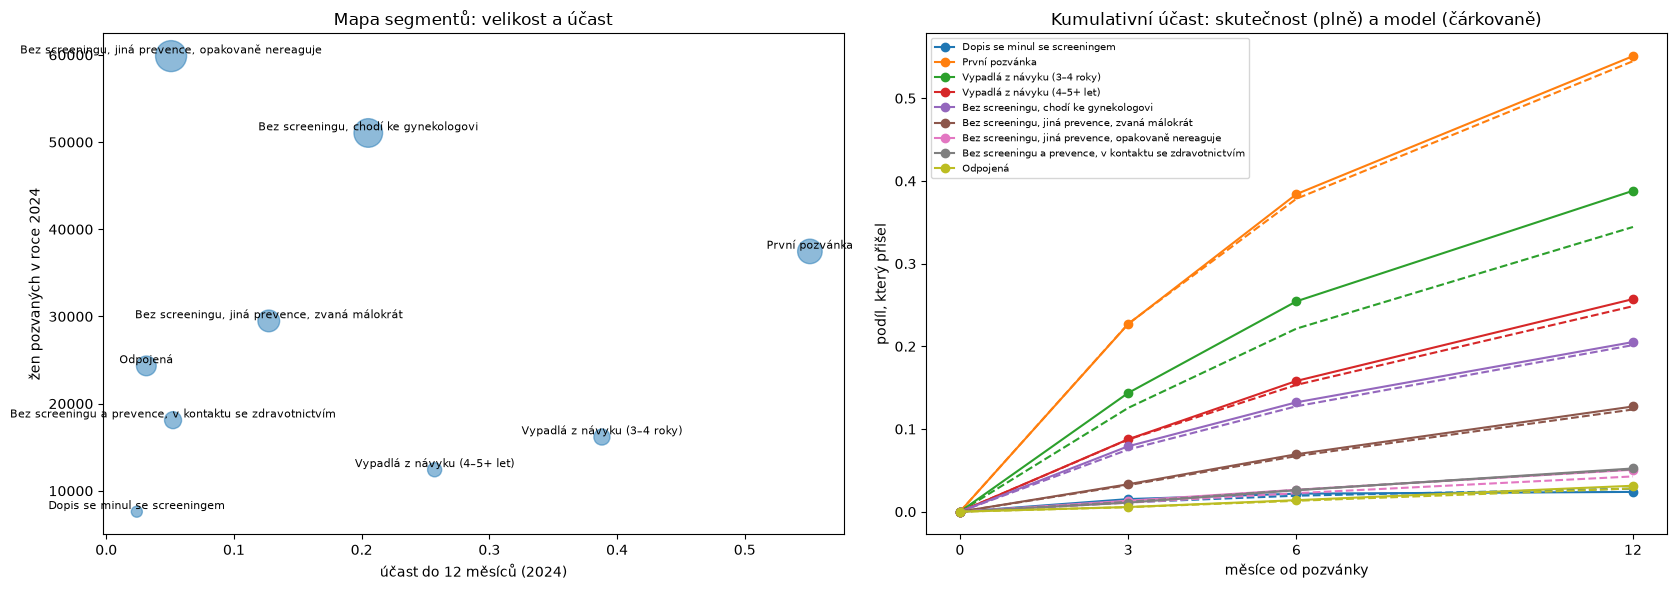

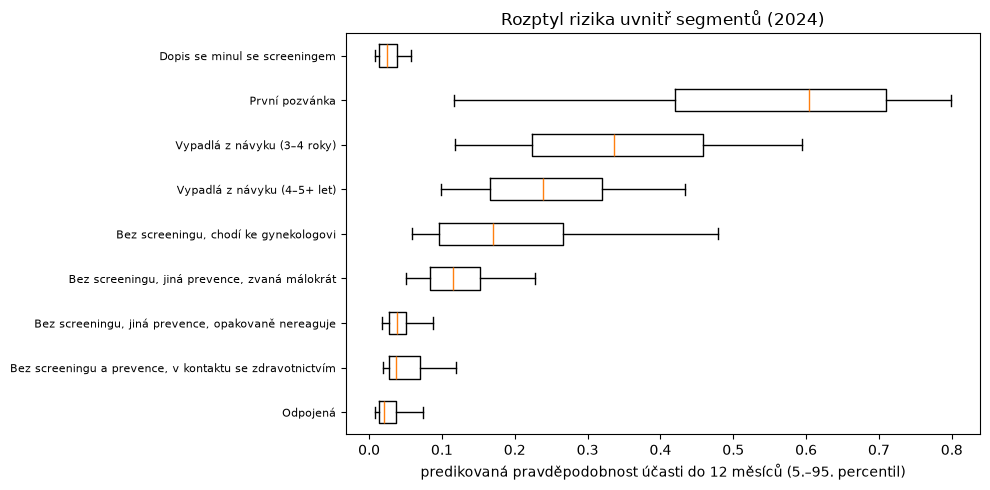

,žen,podíl,účast 3M,predikce 3M,účast 6M,predikce 6M,účast 12M,predikce 12M,AUROC 12M uvnitř,predikce 12M: p10,medián,p90,přijde do 12M (žen),nepřijde do 12M (žen)
segment,,,,,,,,,,,,,,
Dopis se minul se screeningem,"7,600",3.0%,1.5%,1.1%,2.2%,1.9%,2.4%,2.8%,0.658,0.9%,2.4%,5.1%,182,"7,418"
První pozvánka,"37,460",14.6%,22.7%,22.7%,38.4%,37.9%,55.1%,54.5%,0.736,18.0%,60.3%,77.2%,"20,640","16,820"
Vypadlá z návyku (3–4 roky),"16,167",6.3%,14.4%,12.6%,25.4%,22.1%,38.8%,34.4%,0.657,15.0%,33.6%,54.5%,"6,275","9,892"
Vypadlá z návyku (4–5+ let),"12,410",4.8%,8.8%,8.7%,15.8%,15.3%,25.7%,24.9%,0.632,11.9%,23.9%,39.2%,"3,191","9,219"
"Bez screeningu, chodí ke gynekologovi","51,047",19.9%,7.9%,7.5%,13.2%,12.8%,20.5%,20.2%,0.706,6.9%,17.0%,42.2%,"10,474","40,573"
"Bez screeningu, jiná prevence, zvaná málokrát","29,487",11.5%,3.3%,3.2%,7.0%,6.7%,12.7%,12.4%,0.631,6.1%,11.5%,19.5%,"3,753","25,734"
"Bez screeningu, jiná prevence, opakovaně nereaguje","59,864",23.3%,1.3%,1.1%,2.7%,2.2%,5.1%,4.3%,0.639,2.1%,3.8%,7.0%,"3,039","56,825"
"Bez screeningu a prevence, v kontaktu se zdravotnictvím","18,102",7.1%,1.1%,1.2%,2.6%,2.6%,5.2%,5.1%,0.666,2.2%,3.7%,10.3%,947,"17,155"
Odpojená,"24,329",9.5%,0.6%,0.5%,1.4%,1.3%,3.1%,2.8%,0.672,0.9%,2.1%,5.8%,764,"23,565"


In [4]:
rows = []
for s, g in test.groupby("SEGMENT", observed=True):
    r = {"segment": NAZEV[s], "žen": len(g), "podíl": len(g) / len(test)}
    for h, y in zip(HOR, LABELS):
        r[f"účast {h}"] = g[y].mean()
        r[f"predikce {h}"] = g[f"p_{h}"].mean()
    r["AUROC 12M uvnitř"] = roc_auc_score(g[y], g["p_12M"]) if 0 < g[y].mean() < 1 else np.nan
    q = g["p_12M"].quantile([0.1, 0.5, 0.9])
    r["predikce 12M: p10"], r["medián"], r["p90"] = q.values
    r["přijde do 12M (žen)"] = int(g[y].sum())
    r["nepřijde do 12M (žen)"] = int(len(g) - g[y].sum())
    rows.append(r)
S24 = pd.DataFrame(rows).set_index("segment")
S24.to_csv(OUT / "segmenty_2024.csv")

fig, axes = plt.subplots(1, 2, figsize=(17, 6))
ax = axes[0]
ax.scatter(S24["účast 12M"], S24["žen"], s=S24["žen"] / 120, alpha=0.5)
for n, r in S24.iterrows():
    ax.annotate(n, (r["účast 12M"], r["žen"]), fontsize=8, ha="center", va="bottom")
ax.set_xlabel("účast do 12 měsíců (2024)"); ax.set_ylabel("žen pozvaných v roce 2024")
ax.set_title("Mapa segmentů: velikost a účast")
ax = axes[1]
for i, (s, g) in enumerate(test.groupby("SEGMENT", observed=True)):
    ax.plot([0, 3, 6, 12], [0, *g[LABELS].mean()], "-o", color=f"C{i}", label=NAZEV[s])
    ax.plot([0, 3, 6, 12], [0, *g[[f"p_{h}" for h in HOR]].mean()], "--", color=f"C{i}")
ax.set_xticks([0, 3, 6, 12]); ax.set_xlabel("měsíce od pozvánky"); ax.set_ylabel("podíl, který přišel")
ax.set_title("Kumulativní účast: skutečnost (plně) a model (čárkovaně)")
ax.legend(fontsize=7, loc="upper left")
plt.tight_layout(); plt.savefig(OUT / "segmenty_mapa.png", dpi=120); plt.show()

fig, ax = plt.subplots(figsize=(10, 5))
data = [g["p_12M"].values for _, g in test.groupby("SEGMENT", observed=True)]
ax.boxplot(data, orientation="horizontal", showfliers=False, whis=(5, 95))
ax.set_yticks(range(1, len(data) + 1), [NAZEV[s] for s in PORADI], fontsize=8)
ax.invert_yaxis(); ax.set_xlabel("predikovaná pravděpodobnost účasti do 12 měsíců (5.–95. percentil)")
ax.set_title("Rozptyl rizika uvnitř segmentů (2024)")
plt.tight_layout(); plt.savefig(OUT / "segmenty_rozptyl.png", dpi=120); plt.show()
S24.style.format({"žen": "{:,}", "podíl": "{:.1%}", "přijde do 12M (žen)": "{:,}", "nepřijde do 12M (žen)": "{:,}",
                  **{c: "{:.1%}" for c in S24.columns if c.startswith(("účast", "predikce", "medián", "p90"))},
                  "AUROC 12M uvnitř": "{:.3f}"})

**Jak číst.**
* **Mapa (vlevo):** velikost bubliny = počet žen 2024. Vpravo segmenty, které chodí, nahoře velké.
  Pro intervence jsou nejzajímavější velké segmenty se střední účastí (ženy u gynekologa, jiná
  prevence a málo pozvánek): mnoho nepřišlých žen a zároveň rozumná šance, že zareagují.
* **Kumulativní účast (vpravo):** plné čáry skutečnost, čárkované model. Většina žen, které přijdou,
  přijde do 3–6 měsíců. Model sedí ve všech segmentech kromě vypadlých 3–4 roky, kde účast
  podhodnocuje o 4 body: účast tam rok od roku roste a model učený na starších letech to nestíhá.
* **Rozptyl rizika (krabicový graf):** krabice = prostředních 50 % žen, vousy = 5.–95. percentil
  predikce. Široký rozptyl má první pozvánka (p10–p90 18–77 %) a ženy u gynekologa (7–42 %): tam má
  smysl uvnitř segmentu dál cílit podle modelu. Úzký a nízký mají opakovaně nereagující
  a odpojené ženy: model v nich nenajde podskupinu, která by chodila.
* **AUROC uvnitř** (0,63–0,74) je výrazně nižší než celkové 0,84: model rozlišuje hlavně mezi
  segmenty, ne uvnitř nich.
* **Přijde / nepřijde** jsou počty žen v roce 2024. Pro odhad možného přínosu intervence je
  důležitý počet nepřišlých: nejvíc jich je mezi opakovaně nereagujícími (56 800) a ženami
  u gynekologa (40 600).

## 4 · Čím se segmenty liší podle modelu (SHAP)

Přesný TreeSHAP na 20 000 ženách z roku 2024, průměr přes tři intervaly (log-odds hazardu). Tabulka
ukazuje průměrný SHAP sloupce v segmentu: kladný = sloupec v tomto segmentu šanci zvyšuje.

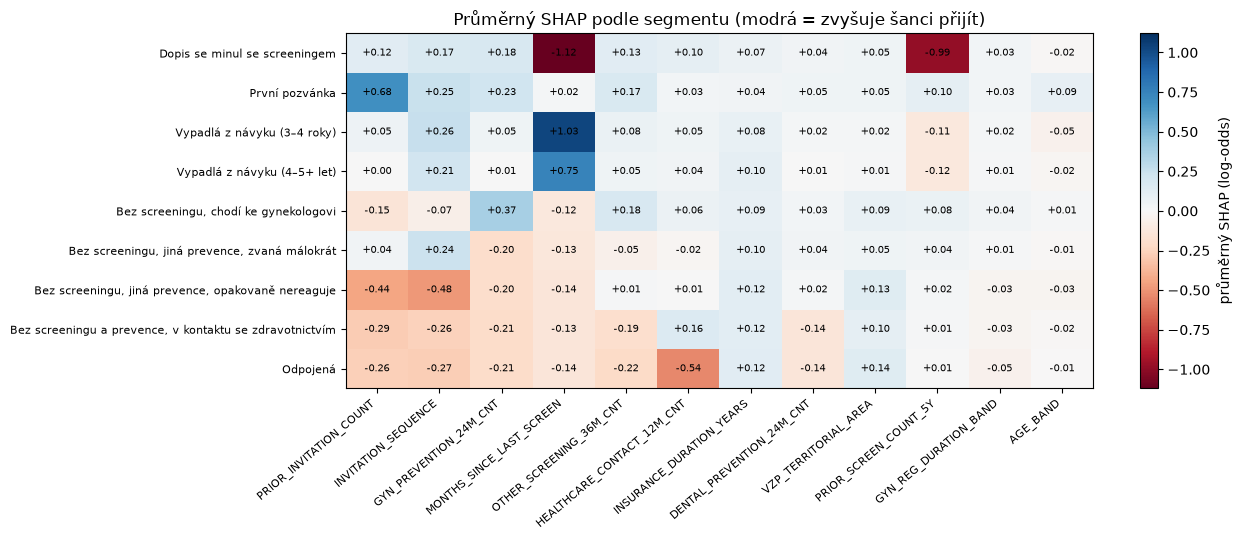

In [5]:
vz = test.sample(20_000, random_state=0)
SV = np.mean([MH.get_feature_importance(Pool(vz[FEATURES].assign(INTERVAL=k), cat_features=CAT),
                                        type="ShapValues")[:, :len(FEATURES)] for k in (1, 2, 3)], axis=0)
SVD = pd.DataFrame(SV, columns=FEATURES, index=vz.index)
top = SVD.abs().mean().sort_values(ascending=False).index[:12]
SEG_SHAP = SVD[top].groupby(vz.SEGMENT, observed=True).mean()
SEG_SHAP.index = [NAZEV[s] for s in SEG_SHAP.index]
SEG_SHAP.round(3).to_csv(OUT / "segmenty_shap.csv")

fig, ax = plt.subplots(figsize=(13, 5.5))
lim = np.abs(SEG_SHAP.values).max()
im = ax.imshow(SEG_SHAP.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(top))); ax.set_xticklabels(top, rotation=40, ha="right", fontsize=8)
ax.set_yticks(range(len(SEG_SHAP))); ax.set_yticklabels(SEG_SHAP.index, fontsize=8)
for i in range(SEG_SHAP.shape[0]):
    for j in range(SEG_SHAP.shape[1]):
        ax.text(j, i, f"{SEG_SHAP.iat[i, j]:+.2f}", ha="center", va="center", fontsize=7)
plt.colorbar(im, ax=ax, label="průměrný SHAP (log-odds)")
ax.set_title("Průměrný SHAP podle segmentu (modrá = zvyšuje šanci přijít)")
plt.tight_layout(); plt.savefig(OUT / "segmenty_shap.png", dpi=120); plt.show()

**Jak číst.** Řádek = segment, sloupec = prediktor, číslo = průměrný SHAP v segmentu; modrá šanci
zvyšuje, červená snižuje. Segmenty se podle modelu liší právě v tom, co je definuje, což je
kontrola, že pravidla dávají smysl:
* **zkřížený dopis:** měsíce od screeningu −1,1 a počet screeningových kódů −1,0 (žena právě byla);
* **první pozvánka:** historie pozvánek +0,69 (žádné dřívější nevyslyšené pozvánky), gynekologie +0,23;
* **vypadlé z návyku:** měsíce od posledního screeningu +0,75 až +1,03 (žena je na řadě a má zkušenost);
* **u gynekologa:** preventivní gynekologie +0,37, historie pozvánek už mírně záporná;
* **tři segmenty bez prevence:** záporná historie pozvánek (−0,26 až −0,48), gynekologie (−0,2)
  a u dvou z nich i jiné screeningy; odpojené ženy navíc málo kontaktů se zdravotnictvím (−0,54).

Územní pracoviště a délka pojištění mají ve všech segmentech podobné malé hodnoty; segmenty
nevysvětlují.

## 5 · Kontrola: shlukování podle SHAP

K-means (k = počet segmentů) na hodnotách SHAP stejných 20 000 žen. Shluky seskupují ženy, které
model „vysvětluje“ podobně. Když shluk nemá jasný převažující segment, pravidla nejspíš
přehlížejí skupinu, kterou model rozlišuje.

In [6]:
km = KMeans(n_clusters=len(SEG), n_init=10, random_state=0).fit(SVD.values)
vz = vz.assign(SHLUK=km.labels_)
ct = pd.crosstab(vz.SHLUK, vz.SEGMENT.map(NAZEV), normalize="index")
SHL = pd.DataFrame({
    "žen": vz.groupby("SHLUK").size(),
    "účast 12M": vz.groupby("SHLUK")[LABELS[2]].mean(),
    "převažující segment": ct.idxmax(axis=1),
    "podíl převažujícího": ct.max(axis=1),
})
prof = SVD.groupby(vz.SHLUK).mean()
SHL["nejvíc zvyšuje"] = prof.idxmax(axis=1) + " (" + prof.max(axis=1).round(2).astype(str) + ")"
SHL["nejvíc snižuje"] = prof.idxmin(axis=1) + " (" + prof.min(axis=1).round(2).astype(str) + ")"
SHL = SHL.sort_values("účast 12M", ascending=False)
SHL.to_csv(OUT / "shap_shluky.csv")
print(f"shoda shluků se segmenty (adjusted Rand): {adjusted_rand_score(vz.SEGMENT.astype(str), vz.SHLUK):.2f}")
display(SHL.style.format({"žen": "{:,}", "účast 12M": "{:.1%}", "podíl převažujícího": "{:.0%}"}))
ct.loc[SHL.index].round(2)

shoda shluků se segmenty (adjusted Rand): 0.49


,žen,účast 12M,převažující segment,podíl převažujícího,nejvíc zvyšuje,nejvíc snižuje
SHLUK,,,,,,
3,"2,834",59.2%,První pozvánka,74%,PRIOR_INVITATION_COUNT (0.62),MONTHS_SINCE_LAST_SCREEN (-0.11)
2,"2,524",35.8%,Vypadlá z návyku (3–4 roky),50%,MONTHS_SINCE_LAST_SCREEN (0.93),PRIOR_SCREEN_COUNT_5Y (-0.13)
7,"1,783",20.5%,"Bez screeningu, chodí ke gynekologovi",99%,GYN_PREVENTION_24M_CNT (0.35),MONTHS_SINCE_LAST_SCREEN (-0.12)
8,"1,462",11.2%,"Bez screeningu, jiná prevence, zvaná málokrát",37%,PRIOR_INVITATION_COUNT (0.34),HEALTHCARE_CONTACT_12M_CNT (-0.33)
1,"2,706",10.8%,"Bez screeningu, jiná prevence, zvaná málokrát",64%,INVITATION_SEQUENCE (0.2),GYN_PREVENTION_24M_CNT (-0.19)
0,"1,401",9.9%,"Bez screeningu, chodí ke gynekologovi",100%,GYN_PREVENTION_24M_CNT (0.41),INVITATION_SEQUENCE (-0.54)
5,"4,763",4.5%,"Bez screeningu, jiná prevence, opakovaně nereaguje",75%,VZP_TERRITORIAL_AREA (0.13),INVITATION_SEQUENCE (-0.53)
4,"1,945",2.6%,Odpojená,58%,VZP_TERRITORIAL_AREA (0.17),HEALTHCARE_CONTACT_12M_CNT (-0.56)
6,582,2.6%,Dopis se minul se screeningem,100%,INVITATION_SEQUENCE (0.19),MONTHS_SINCE_LAST_SCREEN (-1.14)


SEGMENT,Dopis se minul se screeningem,První pozvánka,Vypadlá z návyku (3–4 roky),Vypadlá z návyku (4–5+ let),"Bez screeningu, chodí ke gynekologovi","Bez screeningu, jiná prevence, zvaná málokrát","Bez screeningu, jiná prevence, opakovaně nereaguje","Bez screeningu a prevence, v kontaktu se zdravotnictvím",Odpojená
SHLUK,,,,,,,,,
3,0.0,0.74,0.0,0.00,0.25,0.01,0.00,0.00,0.00
2,0.0,0.14,0.5,0.36,0.00,0.00,0.00,0.00,0.00
7,0.0,0.00,0.0,0.01,0.99,0.00,0.00,0.00,0.00
8,0.0,0.30,0.0,0.00,0.00,0.37,0.00,0.04,0.28
1,0.0,0.00,0.0,0.01,0.00,0.64,0.13,0.16,0.06
0,0.0,0.00,0.0,0.00,1.00,0.00,0.00,0.00,0.00
5,0.0,0.00,0.0,0.00,0.00,0.00,0.75,0.20,0.04
4,0.0,0.00,0.0,0.00,0.01,0.02,0.39,0.00,0.58
6,1.0,0.00,0.0,0.00,0.00,0.00,0.00,0.00,0.00


**Jak číst.** K-means seskupí ženy, u kterých model vysvětluje predikci podobně, bez znalosti pravidel.
První tabulka: velikost shluku, účast, převažující segment s jeho podílem a sloupce, které ve shluku
nejvíc zvyšují a snižují šanci. Druhá tabulka: jak se shluk rozpadá do segmentů (řádky dávají 1).
* **ARI 0,49** (adjusted Rand index; 0 = náhodná shoda, 1 = stejné rozdělení): pravidla a model dělí
  ženy podobně, ne stejně.
* **Čisté shluky** (74–100 %): první pozvánka, zkřížené dopisy, opakovaně nereagující a dva shluky žen
  u gynekologa.
* **Ženy u gynekologa tvoří dva shluky** lišící se historií pozvánek: účast 20 % u zvaných málokrát
  a 10 % u opakovaně zvaných. Kandidát na rozdělení segmentu (stejně jako u jiné prevence).
* **Vypadlé 3–4 a 4+ roky** jsou v jednom shluku spolu s 14 % prvních pozvánek (žen, které už
  screening měly): hranice 48 měsíců je pro model plynulá.
* **Smíšené shluky ukazují druhý rozměr, kontakty se zdravotnictvím.** Jeden shluk (účast 11 %)
  spojuje první pozvánky, ženy s jinou prevencí zvané málokrát a odpojené ženy: všechny mají málo
  pozvánek a málo kontaktů. Jiný (účast 3 %) spojuje odpojené a opakovaně nereagující ženy.
  Pravidla řadí ženy hlavně podle historie screeningu a pozvánek; model k tomu přidává míru kontaktu
  se zdravotnictvím.
* Žádný shluk neobsahuje velkou skupinu, kterou by pravidla úplně přehlížela.

## 6 · Segmenty a navržené páky (hypotézy k experimentu)

In [7]:
PAKY = pd.DataFrame(SEG).set_index("name_cs")[["description_cs", "levers_cs"]]
PAKY = PAKY.join(S24[["žen", "účast 12M"]])
PAKY.columns = ["popis", "páky (hypotéza)", "žen 2024", "účast 12M (2024)"]
PAKY.style.format({"žen 2024": "{:,}", "účast 12M (2024)": "{:.1%}"})

,popis,páky (hypotéza),žen 2024,účast 12M (2024)
name_cs,,,,
Dopis se minul se screeningem,Screening proběhl 0–1 měsíc před dopisem (98 %); systém zvaní o něm ještě nevěděl.,"Žádná intervence; opravit zvaní (ověřit vykázání těsně před odesláním, odklad 1–2 měsíce).","7,600",2.4%
První pozvánka,"První adresná pozvánka, většinou kolem 45. narozenin.","Informace pro ženy, které jdou poprvé, načasování k narozeninám, sociální norma, snadné objednání.","37,460",55.1%
Vypadlá z návyku (3–4 roky),"Screening před 3–4 lety, od té doby ne.","Připomínka s jednoduchým objednáním, plán kdy a kde (implementation intention).","16,167",38.8%
Vypadlá z návyku (4–5+ let),Screening před více než 4 lety.,"Osobnější připomínka (SMS, telefon), doporučení gynekologa.","12,410",25.7%
"Bez screeningu, chodí ke gynekologovi","Za 5 let bez mamografu, ale preventivně chodí ke gynekologovi.",Přes gynekologa: žádanka nebo objednání přímo při prohlídce.,"51,047",20.5%
"Bez screeningu, jiná prevence, zvaná málokrát","Chodí na jinou prevenci (zubař, praktik, jiný screening), pozvánek dostala nejvýš 6.","Připomínka se sociální normou, propojení s jinou prevencí (praktik, zubař), pohodlné termíny.","29,487",12.7%
"Bez screeningu, jiná prevence, opakovaně nereaguje","Chodí na jinou prevenci, ale na 7 a více pozvánek nereagovala.","Dopisy nefungují: jiný kanál (praktik, osobní kontakt), informované rozhodnutí.","59,864",5.1%
"Bez screeningu a prevence, v kontaktu se zdravotnictvím","Žádná prevence, ale aspoň 6 kontaktů se zdravotnictvím za rok.","Oportunisticky přes ošetřující lékaře (praktik, specialisté).","18,102",5.2%
Odpojená,"Bez screeningu, bez prevence, málo kontaktů se zdravotnictvím.","Osobní kontakt a terénní práce; nejtěžší skupina, levné kanály skoro nefungují.","24,329",3.1%


**Jak číst.** Souhrn pro rozhodování: co segment je, jaké páky dávají smysl a kolik žen se ho v roce
2024 týkalo. Páky vycházejí z literatury (`docs/interventions.md`) a z toho, kde ženy už se
zdravotnictvím jsou v kontaktu; **účinek nejsou změřené**. Než se do nějaké páky investuje, má se
ověřit v randomizovaném experimentu na daném segmentu (`07_experiment.ipynb` v původním repozitáři).

## 7 · Zpřesnění pravidel (v2): pomohlo to?

Shlukování v oddílu 5 navrhlo dvě zpřesnění; verze 2 je v `config/segments_vzp_v2.yaml`:
* **první pozvánka podle kontaktů se zdravotnictvím** (< 6 / ≥ 6 za rok),
* **ženy bez screeningu u gynekologa podle počtu pozvánek** (≤ 6 / ≥ 7, stejný práh jako u jiné prevence).

Prahy byly zvolené jen na letech 2020–2023; rok 2024 je čistý test. Kritéria:
1. **predikce ze samotného segmentu**: účast segmentu z let 2020–2023 jako predikce pro 2024 (AUROC,
   log-loss); pro srovnání rozhodovací strom se stejným počtem skupin (datově „nejlepší“ rozdělení
   na 9 nebo 11 skupin) a celý model hazardu;
2. **stabilita**: drží se rozdíl mezi novými podsegmenty každý rok?
3. **shoda se shluky podle SHAP** (ARI);
4. **použitelnost**: velikost nových podsegmentů, počet nepřišlých žen a jiná páka.

In [8]:
from sklearn.metrics import log_loss
from sklearn.tree import DecisionTreeClassifier

SEG2 = yaml.safe_load(open(BASE / "config" / "segments_vzp_v2.yaml", encoding="utf-8"))["segments"]
NAZEV2 = {s["id"]: s["name_cs"] for s in SEG2}

def prirad(df, seg):
    out = pd.Series(pd.NA, index=df.index, dtype="object")
    for s in seg:
        m = df.eval(s["rule"])
        if np.isscalar(m):
            m = pd.Series(bool(m), index=df.index)
        out[out.isna() & m.astype(bool)] = s["id"]
    assert out.notna().all()
    return pd.Categorical(out, categories=[s["id"] for s in seg], ordered=True)

d["SEGMENT2"] = prirad(d, SEG2)
test["SEGMENT2"] = d.loc[test.index, "SEGMENT2"]
vz["SEGMENT2"] = d.loc[vz.index, "SEGMENT2"]
assert (pd.crosstab(d.SEGMENT2, d.SEGMENT) > 0).sum(axis=1).eq(1).all()  # v2 jen zjemňuje v1
uc = (d.INVITATION_DATE < "2024-01-01").values

# 1 · predikce ze samotného segmentu (účast 2020–2023) a strom se stejným počtem skupin
X = d[[c for c in FEATURES if c not in CAT]].fillna(-1)
rows = []
for h, y in zip(HOR, LABELS):
    yt = d.loc[~uc, y].values
    r = {"horizont": h, "model hazardu": roc_auc_score(test[y], test[f"p_{h}"])}
    for nm, col in [("v1 (9)", "SEGMENT"), ("v2 (11)", "SEGMENT2")]:
        uc_seg = d[uc].groupby(col, observed=True)[y].mean()
        p = d.loc[~uc, col].astype(str).map(uc_seg.rename(index=str)).values
        r[f"AUROC {nm}"], r[f"log-loss {nm}"] = roc_auc_score(yt, p), log_loss(yt, p)
    for k in (9, 11):
        t = DecisionTreeClassifier(max_leaf_nodes=k, min_samples_leaf=1000, random_state=0).fit(X[uc], d.loc[uc, y])
        p = t.predict_proba(X[~uc])[:, 1]
        r[f"AUROC strom {k}"], r[f"log-loss strom {k}"] = roc_auc_score(yt, p), log_loss(yt, p)
    rows.append(r)
PRED = pd.DataFrame(rows).set_index("horizont")
PRED.to_csv(OUT / "v2_predikce.csv")

# 2 · stabilita nových podsegmentů po letech
NOVE = ["prvni_pozvanka_malo_kontaktu", "prvni_pozvanka", "nikdy_gynekolog_malo_zvana", "nikdy_gynekolog_nereaguje"]
sub = d[d.SEGMENT2.isin(NOVE)].assign(rok=lambda x: x.INVITATION_DATE.dt.year)
STAB = sub.pivot_table(index="SEGMENT2", columns="rok", values=LABELS[2], aggfunc="mean", observed=True)
STAB.index = [NAZEV2[s] for s in STAB.index]
STAB.to_csv(OUT / "v2_stabilita.csv")

# 3 · shoda se shluky podle SHAP
km11 = KMeans(n_clusters=len(SEG2), n_init=10, random_state=0).fit(SVD.values)
ARI = pd.DataFrame({f"shluky k = {len(SEG)}": [adjusted_rand_score(vz[c].astype(str), vz.SHLUK) for c in ["SEGMENT", "SEGMENT2"]],
                    f"shluky k = {len(SEG2)}": [adjusted_rand_score(vz[c].astype(str), km11.labels_) for c in ["SEGMENT", "SEGMENT2"]]},
                   index=["v1 (9 segmentů)", "v2 (11 segmentů)"])

# 4 · nové podsegmenty v roce 2024
rows = []
for s in NOVE:
    g = test[test.SEGMENT2 == s]
    y = LABELS[2]
    rows.append({"segment": NAZEV2[s], "žen 2024": len(g), "účast 12M": g[y].mean(), "predikce 12M": g.p_12M.mean(),
                 "nepřišlo": int(len(g) - g[y].sum()), "AUROC 12M uvnitř": roc_auc_score(g[y], g.p_12M),
                 "páka": next(x["levers_cs"] for x in SEG2 if x["id"] == s)})
POD2 = pd.DataFrame(rows).set_index("segment")
POD2.to_csv(OUT / "v2_nove_podsegmenty.csv")

print("1 · AUROC a log-loss na roce 2024 (účast segmentu z 2020–2023)")
display(PRED.round(4))
print("2 · účast do 12 měsíců po letech v nových podsegmentech")
display(STAB.style.format("{:.1%}"))
print("3 · shoda se shluky podle SHAP (ARI)")
display(ARI.round(3))
print("4 · nové podsegmenty v roce 2024")
POD2.style.format({"žen 2024": "{:,}", "nepřišlo": "{:,}", "účast 12M": "{:.1%}", "predikce 12M": "{:.1%}",
                   "AUROC 12M uvnitř": "{:.3f}"})

1 · AUROC a log-loss na roce 2024 (účast segmentu z 2020–2023)


,model hazardu,AUROC v1 (9),log-loss v1 (9),AUROC v2 (11),log-loss v2 (11),AUROC strom 9,log-loss strom 9,AUROC strom 11,log-loss strom 11
horizont,,,,,,,,,
3M,0.8350,0.7903,0.2171,0.8007,0.2144,0.7901,0.2139,0.7936,0.2131
6M,0.8356,0.7959,0.3087,0.8055,0.3042,0.7931,0.3048,0.7959,0.3025
12M,0.8362,0.7973,0.3939,0.8072,0.3871,0.7903,0.3889,0.7933,0.3855


2 · účast do 12 měsíců po letech v nových podsegmentech


rok,2020,2021,2022,2023,2024
"První pozvánka, málo kontaktů",30.6%,28.1%,28.3%,34.4%,35.7%
"První pozvánka, v kontaktu",52.8%,57.6%,57.7%,59.7%,59.6%
"Bez screeningu, gynekolog, zvaná málokrát",24.5%,26.3%,26.8%,27.5%,27.1%
"Bez screeningu, gynekolog, opakovaně nereaguje",7.4%,7.9%,8.8%,10.7%,10.3%


3 · shoda se shluky podle SHAP (ARI)


,shluky k = 9,shluky k = 11
v1 (9 segmentů),0.489,0.416
v2 (11 segmentů),0.524,0.446


4 · nové podsegmenty v roce 2024


,žen 2024,účast 12M,predikce 12M,nepřišlo,AUROC 12M uvnitř,páka
segment,,,,,,
"První pozvánka, málo kontaktů","7,127",35.7%,33.4%,"4,580",0.790,"Osobnější první kontakt (SMS, telefon, praktik), jednoduché vysvětlení, snadné objednání."
"První pozvánka, v kontaktu","30,333",59.6%,59.4%,"12,240",0.702,"Informace pro ženy, které jdou poprvé, načasování k narozeninám, sociální norma, snadné objednání."
"Bez screeningu, gynekolog, zvaná málokrát","31,098",27.1%,27.1%,"22,679",0.661,"Připomínka s odkazem na gynekologa, žádanka při nejbližší prohlídce."
"Bez screeningu, gynekolog, opakovaně nereaguje","19,949",10.3%,9.3%,"17,894",0.606,Dopisy nefungují: aktivní role gynekologa (objednání přímo při prohlídce).


**Verdikt: ano, obě zpřesnění pomohla, i když skromně.**
* **Predikce:** samotné segmenty v2 dávají na roce 2024 AUROC 0,807 proti 0,797 u v1 (do 12 měsíců,
  podobně pro 3 a 6 měsíců) a nižší log-loss. Mezeru k plnému modelu (0,836) tak zmenšují zhruba
  o čtvrtinu. Ruční pravidla jsou přitom v AUROC lepší než rozhodovací strom se stejným počtem
  skupin (0,793 pro 11 listů) a v log-loss téměř stejná (0,387 proti 0,386): o moc lepší rozdělení
  na 11 skupin z těchto sloupců nejde.
* **Stabilita:** rozdíly drží každý rok 2020–2024: první pozvánka 28–36 % (málo kontaktů) proti
  53–60 % (v kontaktu), ženy u gynekologa 24–28 % (zvané málokrát) proti 7–11 % (opakovaně
  nereaguje). Nejde o náhodu jednoho roku.
* **Shoda se shluky:** ARI stoupla z 0,49 na 0,52 (k = 9) a z 0,42 na 0,45 (k = 11).
* **Použitelnost:** větší dopad má rozdělení žen u gynekologa: 22 700 nepřišlých zvaných málokrát
  (účast 27 %) a 17 900 opakovaně nereagujících (10 %), u kterých dopis zjevně nefunguje a dává
  smysl aktivní role gynekologa. První pozvánka s málo kontakty je malá (7 100 žen, 4 600
  nepřišlých), ale jasně odlišná (účast 36 % proti 60 %) a model v ní rozlišuje dobře (AUROC 0,79).
* **Cena:** dva segmenty navíc (11 místo 9); pravidla zůstávají jednoduchá.

**Doporučení:** používat v2 jako hlavní pravidla. Další zpřesňování má klesající výnos: zbývající
mezera k plnému modelu (asi 0,03 AUROC) je rozptýlená po mnoha sloupcích, ne v jedné přehlédnuté
skupině.

## Interpretace

**Velikost a účast (oddíly 1 a 3).** Segmenty jsou v čase stabilní a účast v nich roste mírně
(první pozvánka 48 % → 55 % od 2020 do 2024, opakovaně nereagující 3 % → 5 %). Model je uvnitř
segmentů dobře kalibrovaný, jen u vypadlých 3–4 roky podhodnocuje (34 % predikce proti 39 %), kde
účast rok od roku roste.

**Segment po segmentu (2024):**
* **Dopis se minul se screeningem** (7 600 žen, 3 %): 2,4 % účast, protože screening právě měly.
  Úspora na zvaní, ne cíl intervence.
* **První pozvánka** (37 500, 15 %): nejvyšší účast (55 %), ale také největší rozptyl uvnitř
  (predikce 18–77 % mezi 10. a 90. percentilem). Rozhoduje, jestli žena chodí ke gynekologovi
  a na jiný screening. 16 800 žen nepřišlo; první zkušenost určuje návyk, takže právě tady se
  vyplatí investovat.
* **Vypadlé z návyku** (28 600, 11 %): 39 % a 26 % účast. Mají zkušenost, stačí jim nejspíš
  připomínka a snadné objednání; vyšší účast než ženy bez screeningu.
* **Bez screeningu, chodí ke gynekologovi** (51 000, 20 %): 21 % účast, 40 600 nepřišlo. Největší
  dosažitelná skupina: gynekolog je vidí aspoň jednou za 2 roky. SHAP shluky ji dělí na ženy
  zvané málokrát (účast 20 %) a opakovaně zvané (10 %).
* **Bez screeningu, jiná prevence, zvaná málokrát** (29 500, 12 %): 13 % účast. Chodí k zubaři či
  praktikovi na prevenci, ne ke gynekologovi; cesta přes praktika nebo zubaře.
* **Bez screeningu, jiná prevence, opakovaně nereaguje** (59 900, 23 %): jen 5 % účast po 7 a více
  pozvánkách. Největší skupina nepřišlých (56 800). Další dopis skoro nic nepřinese; pokud vůbec,
  tak jiný kanál (praktik, který je vidí na prevenci) nebo informované rozhodnutí.
* **Bez screeningu a prevence, v kontaktu se zdravotnictvím** (18 100, 7 %): 5 % účast; aspoň
  6 kontaktů za rok, ale žádná prevence. Oportunisticky přes ošetřující lékaře.
* **Odpojená** (24 300, 9 %): 3 % účast, málo kontaktů se zdravotnictvím. Nejtěžší skupina;
  levné kanály skoro nefungují.

**Co ukazuje SHAP (oddíl 4).** Segmenty se liší přesně v tom, podle čeho jsou definované:
u první pozvánky táhne šanci nahoru historie pozvánek (+0,69), u vypadlých měsíce od posledního
screeningu (+0,75 až +1,03), u žen u gynekologa preventivní gynekologie (+0,37). Tři segmenty bez
prevence mají záporné téměř všechno, nejvíc historii pozvánek (−0,26 až −0,48); odpojené navíc
málo kontaktů se zdravotnictvím (−0,54).

**Kontrola shlukováním (oddíl 5).** Shluky víceméně kopírují segmenty: první pozvánka, gynekolog,
opakovaně nereagující a zkřížené dopisy mají vlastní shluky (převažující segment 74–100 %).
Méně ostré jsou hranice mezi vypadlými 3–4 a 4+ roky a mezi skupinami s jinou prevencí. Žádný shluk
neukazuje velkou skupinu, kterou by pravidla úplně přehlížela. Doporučené zpřesnění: rozdělit
ženy u gynekologa podle počtu pozvánek (stejně jako skupinu s jinou prevencí).

**Doporučení.** Pro VZP jsou tři priority: (1) **první pozvánka**, protože tvoří návyk a účast je
vysoká, takže každý další bod je levný; (2) **ženy u gynekologa** a **ženy s jinou prevencí**,
celkem třetina nepřišlých, dosažitelné přes lékaře, kterého už navštěvují; (3) **opravit zvaní**
(zkřížené dopisy). Opakovaně nereagující a odpojené ženy dopisem nezískáme; tam jde o dražší
osobní kanály a o to, zda je vůbec dál zvát stejně. Všechny páky jsou hypotézy pro experiment.

## Poznámky a omezení

* **Segmenty popisují, kdo přijde, ne kdo přijde díky intervenci.** Páky jsou hypotézy; o účinku
  rozhodne experiment (`07_experiment.ipynb` v původním repozitáři, `docs/interventions.md`).
* **„Bez screeningu“ = žádný z kódů štítků za posledních 5 let**; ženy, které na mamograf šly dřív,
  jsou v datech nerozlišené od žen, které nebyly nikdy.
* **Prahy pravidel** (6 pozvánek, 6 kontaktů, 48 měsíců) jsou zvolené podle rozložení a SHAP
  křivek, ne optimalizované; lze je ladit v `config/segments_vzp.yaml`.
* **Chybí sloupce** pro segmenty z `03_segmentace.ipynb` v původním repozitáři: hospitalizace a chronické nemoci,
  vzdálenost k centru, věk 75+. Územní pracoviště VZP není okres, okresní ukazatele (dostupnost,
  socioekonomika) proto napojit nejde.
* **V datech nejsou nově pojištěné ženy** (jen nepřetržitě pojištěné 2015–2025).